In [59]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/train.csv")
print(df.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')


In [60]:
print("None")
print(df.isna().sum())

None
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


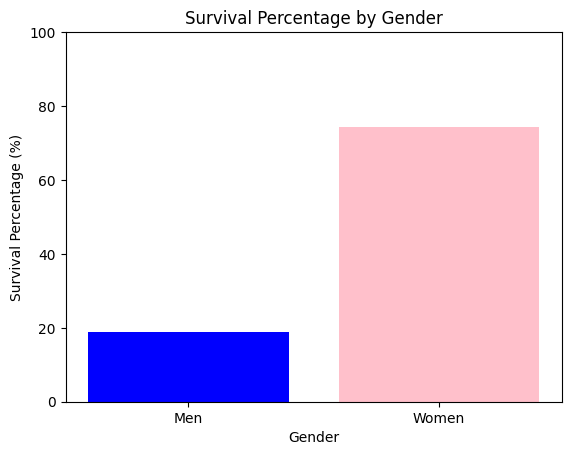

In [61]:
# Men
survived_men = df[(df["Sex"] == "male") & (df["Survived"] == 1)]
men_nbr = df[df["Sex"] == "male"]

num_survived_men = len(survived_men)
num_men = len(men_nbr)

# Women
survived_women = df[(df["Sex"] == "female") & (df["Survived"] == 1)]
women_nbr = df[df["Sex"] == "female"]

num_survived_women = len(survived_women)
num_women = len(women_nbr)

# Calculate percentages
men_percent = num_survived_men / num_men * 100
women_percent = num_survived_women / num_women * 100

genders = ["Men", "Women"]
percentages = [men_percent, women_percent]

# Plot
plt.bar(genders, percentages, color=["blue", "pink"])
plt.xlabel("Gender")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by Gender")
plt.ylim(0, 100)
plt.show()


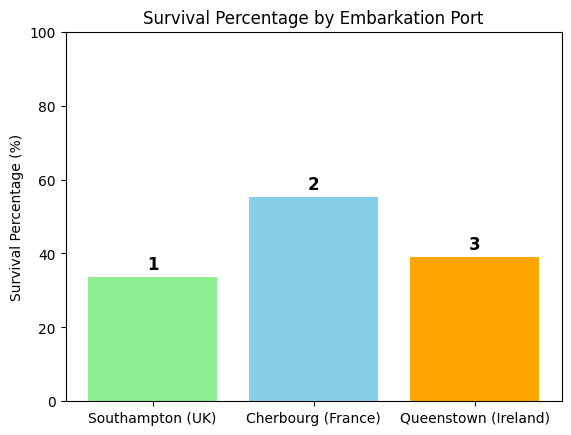

In [ ]:
# Chronological order of Titanic's route
embarked_points = ["S", "C", "Q"]
embarked_map = {"C": "Cherbourg (France)", "Q": "Queenstown (Ireland)", "S": "Southampton (UK)"}

percentages = []

# Calculate survival percentage in order
for port in embarked_points:
    total = len(df[df["Embarked"] == port])
    survived = len(df[(df["Embarked"] == port) & (df["Survived"] == 1)])
    percentages.append(survived / total * 100)

# Labels for x-axis
labels = [embarked_map[port] for port in embarked_points]

# Chronology numbers
chronology = [1, 2, 3]  # Southampton=1, Cherbourg=2, Queenstown=3

# Plot
fig, ax = plt.subplots()
bars = ax.bar(labels, percentages, color=["lightgreen", "skyblue", "orange"])
ax.set_ylabel("Survival Percentage (%)")
ax.set_title("Survival Percentage by Embarkation Port")
ax.set_ylim(0, 100)

# Add chronology number on top of each bar
for bar, order in zip(bars, chronology):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        str(order),
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.show()

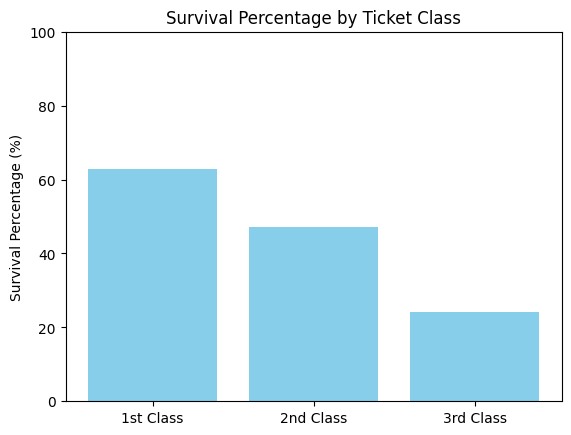

In [63]:
# Ticket classes
classes = [1, 2, 3]

# Calculate survival percentages
percentages = [
    len(df[(df["Pclass"] == cls) & (df["Survived"] == 1)]) / len(df[df["Pclass"] == cls]) * 100
    for cls in classes
]

# Plot
plt.bar(["1st Class", "2nd Class", "3rd Class"], percentages, color="skyblue")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by Ticket Class")
plt.ylim(0, 100)



plt.show()

In [64]:
# Unique numbers for SibSp (siblings/spouses)
unique_sibsp = sorted(df["SibSp"].unique())
print("Unique SibSp values:", unique_sibsp)

# Unique numbers for Parch (parents/children)
unique_parch = sorted(df["Parch"].unique())
print("Unique Parch values:", unique_parch)


Unique SibSp values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(8)]
Unique Parch values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


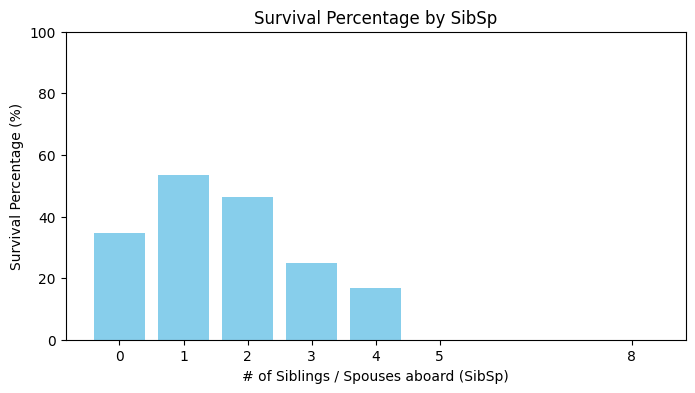

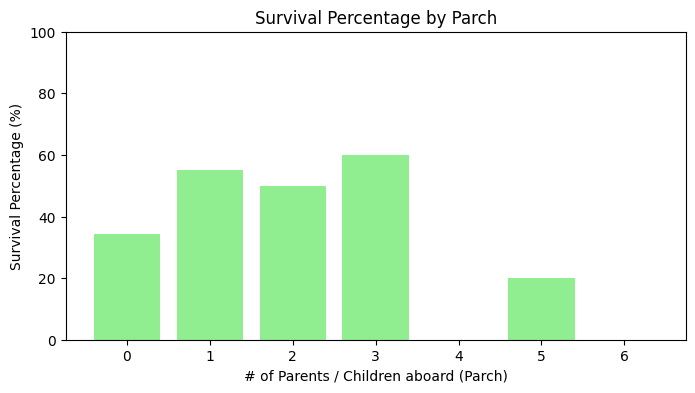

In [65]:

# --- Survival percentage by SibSp ---
sibsp_total = df.groupby("SibSp")["Survived"].count()   # total passengers per SibSp
sibsp_survived = df.groupby("SibSp")["Survived"].sum()  # total survivors per SibSp

sibsp_percent = sibsp_survived / sibsp_total * 100      # calculate percentage

plt.figure(figsize=(8, 4))
plt.bar(sibsp_percent.index, sibsp_percent.values, color="skyblue")
plt.xlabel("# of Siblings / Spouses aboard (SibSp)")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by SibSp")
plt.ylim(0, 100)
plt.xticks(sibsp_percent.index)
plt.show()


# --- Survival percentage by Parch ---
parch_total = df.groupby("Parch")["Survived"].count()   # total passengers per Parch
parch_survived = df.groupby("Parch")["Survived"].sum()  # total survivors per Parch

parch_percent = parch_survived / parch_total * 100      # calculate percentage

plt.figure(figsize=(8, 4))
plt.bar(parch_percent.index, parch_percent.values, color="lightgreen")
plt.xlabel("# of Parents / Children aboard (Parch)")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by Parch")
plt.ylim(0, 100)
plt.xticks(parch_percent.index)
plt.show()